# Soal 3: K-Means pada Dataset clustering.csv

**Nama:** Christina Adelia Sitinjak  
**NIM:** 42324056  
**Mata Kuliah:** 4233201 - Kecerdasan Buatan  
**Topik:** Menentukan K Optimal dan Klasterisasi K-Means

> Letakkan file `clustering.csv` di folder yang sama dengan notebook ini, lalu jalankan sel dari atas ke bawah (Run All).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Membaca dataset clustering.csv
df = pd.read_csv('clustering.csv')
df.head()

,User ID,Instagram visit score,Spending_rank(0 to 100)
0,0,63,24.050708
1,1,61,25.223290
2,2,104,18.528245
3,3,82,86.890232
4,4,14,31.492397


#### Penjelasan:

Kode di atas untuk menyiapkan library yang dipakai, lalu membaca file `clustering.csv` dan melihat sekilas isinya.

`pandas` (`pd`) dipakai untuk mengolah data tabel, `numpy` (`np`) untuk hitungan angka, `matplotlib.pyplot` (`plt`) dan `seaborn` (`sns`) untuk membuat grafik. Baris `pd.read_csv('clustering.csv')` membaca file dan menyimpannya di `df`, lalu `df.head()` menampilkan 5 baris teratas.

**Cara membaca hasil:** setiap baris adalah satu pengguna. Kolom `User ID` adalah nomor pengguna, `Instagram visit score` adalah skor seberapa sering pengguna mengunjungi Instagram, dan `Spending_rank(0 to 100)` adalah peringkat pengeluaran pengguna dalam skala 0 sampai 100. Makin tinggi angkanya, makin besar pengeluarannya.

**Catatan:** file `clustering.csv` harus berada di folder yang sama dengan notebook ini.


In [2]:
# Ukuran data, tipe data, dan jumlah missing value
print("Ukuran data (baris, kolom):", df.shape)
print()
print(df.dtypes)
print()
print("Missing value per kolom:")
print(df.isnull().sum())

Ukuran data (baris, kolom): (2600, 3)

User ID                      int64
Instagram visit score        int64
Spending_rank(0 to 100)    float64
dtype: object

Missing value per kolom:
User ID                    0
Instagram visit score      0
Spending_rank(0 to 100)    0
dtype: int64


#### Penjelasan:

Kode di atas untuk mengenali data lebih dulu: ukurannya, tipe tiap kolom, dan ada tidaknya data kosong.

`df.shape` menampilkan jumlah baris dan kolom, `df.dtypes` menampilkan tipe data tiap kolom, dan `df.isnull().sum()` menghitung jumlah sel kosong per kolom.

**Cara membaca hasil:** datanya berukuran **2.600 baris dan 3 kolom**. Kolom `User ID` dan `Instagram visit score` bertipe `int64` (angka bulat), dan `Spending_rank(0 to 100)` bertipe `float64` (angka desimal). Jumlah missing value di ketiga kolom adalah **0**, jadi data lengkap dan bisa langsung dipakai.


In [3]:
# Membuang kolom User ID (hanya penanda pengguna) lalu melihat statistik ringkas
data = df.drop(columns='User ID')
data.describe()

,Instagram visit score,Spending_rank(0 to 100)
count,2600.000000,2600.000000
mean,63.323462,42.848408
std,26.579760,28.758349
min,5.000000,0.940709
25%,38.000000,19.452098
50%,72.000000,28.013082
75%,86.000000,72.116945
max,118.000000,107.349821


#### Penjelasan:

Kode di atas untuk membuang kolom `User ID`, lalu melihat statistik ringkas dari dua kolom yang tersisa.

Kolom `User ID` hanya penanda pengguna. Isinya urutan angka 0 sampai 2599 yang tidak punya arti untuk pengelompokan. Kalau ikut dipakai, K-Means akan menganggapnya sebagai ciri pengguna dan hasil klasternya bisa melenceng. Karena itu dibuang dengan `df.drop(columns='User ID')`, dan hasilnya disimpan di `data`. Lalu `data.describe()` menampilkan ringkasan statistik tiap kolom.

**Cara membaca hasil:** baris `count` menunjukkan 2.600 data di tiap kolom. Pada `Instagram visit score`, rata-ratanya sekitar **63,3**, nilai terkecilnya 5, dan terbesarnya 118. Pada `Spending_rank(0 to 100)`, rata-ratanya sekitar **42,8**, nilai terkecilnya sekitar 0,94, dan terbesarnya sekitar 107,35.

Ada satu hal yang menarik. Walaupun judul kolomnya "0 to 100", nilai maksimumnya 107,35. Ada 14 baris yang nilainya di atas 100. Selisihnya kecil, jadi data tetap dipakai apa adanya. Sebaran kedua kolom juga mirip (standar deviasi sekitar 26,6 dan 28,8), jadi skala keduanya sebanding dan tidak perlu standarisasi.


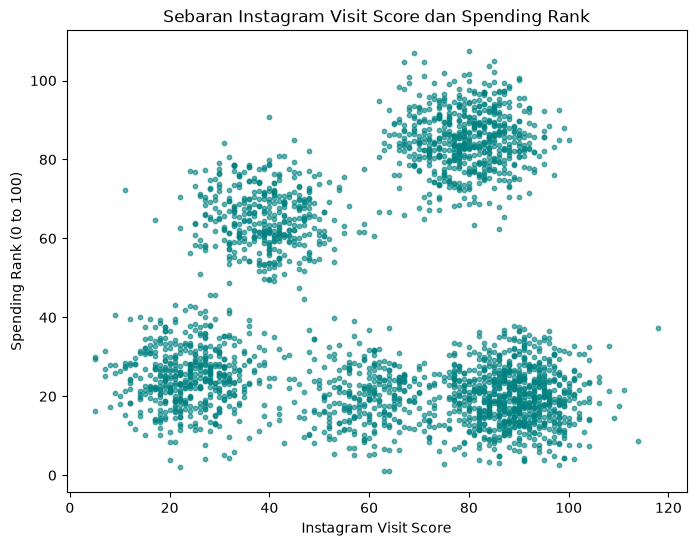

In [4]:
# Melihat sebaran data sebelum diklasterkan
plt.figure(figsize=(8, 6))
plt.scatter(data['Instagram visit score'], data['Spending_rank(0 to 100)'], s=10, color='teal', alpha=0.6)
plt.title('Sebaran Instagram Visit Score dan Spending Rank')
plt.xlabel('Instagram Visit Score')
plt.ylabel('Spending Rank (0 to 100)')
plt.show()

#### Penjelasan:

Kode di atas untuk menampilkan sebaran data dalam bentuk grafik titik sebelum dikelompokkan.

Baris `plt.scatter(x, y, s=10, color='teal', alpha=0.6)` menggambar satu titik untuk setiap pengguna, dengan `Instagram visit score` di sumbu x dan `Spending rank` di sumbu y. Pengaturan `s=10` mengatur ukuran titik (dibuat kecil karena ada 2.600 titik), `color='teal'` memilih warna hijau kebiruan, dan `alpha=0.6` membuat titik agak transparan supaya area yang padat terlihat lebih pekat. Sisanya memberi judul dan nama sumbu.

**Cara membaca hasil:** titik-titik terlihat tidak menyebar merata, tetapi mengumpul menjadi beberapa kelompok. Ada kelompok di kanan bawah (visit tinggi, spending rendah), kelompok di kiri bawah (visit rendah, spending rendah), kelompok di kiri-tengah atas (visit sedang, spending agak tinggi), dan kelompok di kanan atas (visit tinggi, spending sangat tinggi). Jadi sekilas terlihat ada sekitar 4 kelompok. Langkah berikutnya adalah membuktikannya dengan angka, yaitu mencari nilai K yang optimal.


---
## Menentukan Nilai K Optimal

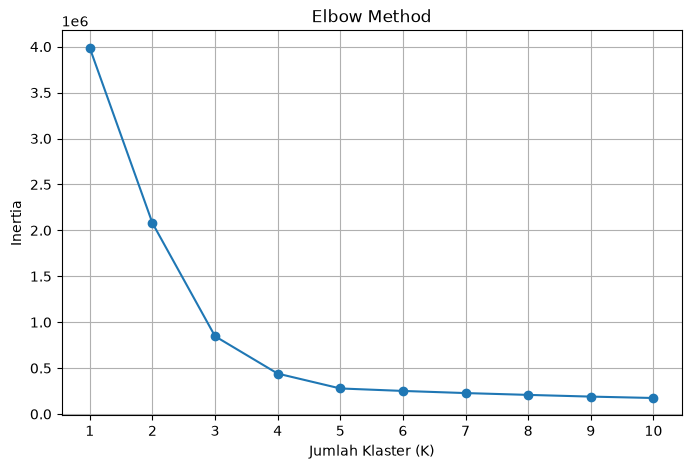

In [5]:
# Menentukan K optimal (1) - Elbow Method
from sklearn.cluster import KMeans

inertia = []
rentang_k = range(1, 11)
for k in rentang_k:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    model.fit(data)
    inertia.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(rentang_k, inertia, marker='o')
plt.title('Elbow Method')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Inertia')
plt.xticks(rentang_k)
plt.grid(True)
plt.show()

#### Penjelasan:

Kode di atas untuk menentukan nilai K optimal dengan **Elbow Method** (metode siku). Ini cara pertama dari dua cara yang dipakai.

K-Means mengelompokkan data menjadi K klaster, tetapi K harus ditentukan oleh kita. Elbow Method mencoba banyak nilai K, lalu melihat seberapa rapat klaster yang terbentuk. Ukuran kerapatannya disebut **inertia**, yaitu jumlah kuadrat jarak setiap titik ke pusat klasternya. Makin kecil inertia, makin rapat klasternya.

Perulangan `for k in rentang_k` mencoba K dari 1 sampai 10. Untuk tiap K, `KMeans(n_clusters=k, n_init=10, random_state=42)` membuat model. Pengaturan `n_init=10` berarti algoritma dijalankan 10 kali dengan titik awal berbeda dan hasil terbaik dipakai. Pengaturan `random_state=42` mengunci pengacakan supaya hasilnya sama setiap dijalankan. Lalu `model.fit(data)` melatih model, dan `model.inertia_` mengambil nilai inertia-nya, yang dikumpulkan di daftar `inertia`. Setelah itu grafik K terhadap inertia digambar.

**Cara membaca hasil:** inertia pasti makin kecil kalau K makin besar (sampai K = jumlah data, inertia menjadi 0), jadi kita tidak mencari inertia terkecil. Yang dicari adalah titik "siku", yaitu tempat penurunan grafik berubah dari curam menjadi landai. Pada grafik ini, inertia turun tajam dari K = 1 ke 2, lalu ke 3, lalu ke 4, dan setelah K = 4 atau 5 grafiknya mendatar. Jadi sikunya ada di sekitar **K = 4**. Karena bentuk siku kadang bisa diperdebatkan (bisa terlihat di 4 atau 5), cara kedua dipakai untuk memastikan.


K = 2 -> silhouette score = 0.4900
K = 3 -> silhouette score = 0.5954
K = 4 -> silhouette score = 0.6468
K = 5 -> silhouette score = 0.6201
K = 6 -> silhouette score = 0.5394
K = 7 -> silhouette score = 0.4483
K = 8 -> silhouette score = 0.4463
K = 9 -> silhouette score = 0.3837
K = 10 -> silhouette score = 0.3392

K optimal berdasarkan silhouette score: 4


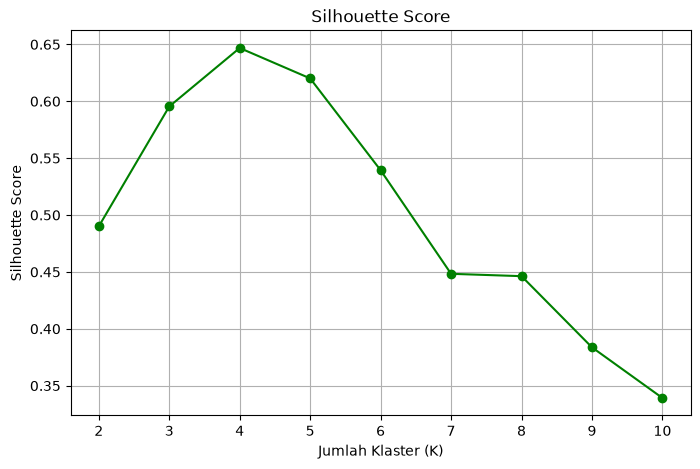

In [6]:
# Menentukan K optimal (2) - Silhouette Score
from sklearn.metrics import silhouette_score

skor_silhouette = []
rentang_k2 = range(2, 11)
for k in rentang_k2:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    label = model.fit_predict(data)
    skor_silhouette.append(silhouette_score(data, label))
    print(f"K = {k} -> silhouette score = {skor_silhouette[-1]:.4f}")

k_optimal = list(rentang_k2)[int(np.argmax(skor_silhouette))]
print()
print("K optimal berdasarkan silhouette score:", k_optimal)

plt.figure(figsize=(8, 5))
plt.plot(rentang_k2, skor_silhouette, marker='o', color='green')
plt.title('Silhouette Score')
plt.xlabel('Jumlah Klaster (K)')
plt.ylabel('Silhouette Score')
plt.xticks(rentang_k2)
plt.grid(True)
plt.show()

#### Penjelasan:

Kode di atas untuk menentukan nilai K optimal dengan **Silhouette Score**. Ini cara kedua, dan hasilnya lebih pasti dibanding Elbow Method karena menghasilkan satu angka untuk dibandingkan.

Silhouette score menilai seberapa cocok setiap titik dengan klasternya sendiri dibandingkan dengan klaster terdekat lainnya. Nilainya berkisar dari -1 sampai 1. Makin mendekati 1, makin rapat dan terpisah jelas klasternya. Nilai sekitar 0 berarti klaster saling tumpang tindih. Nilai negatif berarti banyak titik salah klaster.

Perulangan `for k in rentang_k2` mencoba K dari 2 sampai 10 (K = 1 tidak dipakai karena silhouette butuh minimal 2 klaster). Untuk tiap K, `model.fit_predict(data)` melatih model sekaligus menghasilkan nomor klaster tiap titik, lalu `silhouette_score(data, label)` menghitung nilainya. Baris `np.argmax(skor_silhouette)` mencari posisi skor tertinggi, dan dari situ diambil K-nya dan disimpan di `k_optimal`. Variabel ini dipakai di sel-sel berikutnya.

**Cara membaca hasil:** skor tertinggi ada pada **K = 4 dengan nilai 0,6468**. Sebagai perbandingan, K = 3 bernilai 0,5954, K = 5 bernilai 0,6201, K = 2 bernilai 0,4900, dan skor terus turun sampai 0,3392 pada K = 10. Nilai 0,65 termasuk **baik** (di atas 0,5 sudah dianggap struktur klaster yang cukup kuat). Jadi **K optimal = 4**, sesuai dengan Elbow Method dan dengan pengamatan di grafik sebaran.


---
## Klasterisasi dengan K-Means

In [7]:
# Klasterisasi dengan K-Means memakai K optimal
kmeans = KMeans(n_clusters=k_optimal, n_init=10, random_state=42)
data = data.copy()
data['Klaster'] = kmeans.fit_predict(data[['Instagram visit score', 'Spending_rank(0 to 100)']])

pusat = kmeans.cluster_centers_
print("Pusat klaster (Instagram visit score, Spending rank):")
print(pusat.round(2))
print()
print("Jumlah anggota tiap klaster:")
print(data['Klaster'].value_counts().sort_index())

Pusat klaster (Instagram visit score, Spending rank):
[[83.24 19.87]
 [39.35 65.13]
 [79.62 85.02]
 [27.3  24.31]]

Jumlah anggota tiap klaster:
Klaster
0    1027
1     400
2     600
3     573
Name: count, dtype: int64


#### Penjelasan:

Kode di atas untuk mengelompokkan data dengan K-Means memakai K optimal, yaitu 4, lalu menampilkan pusat dan jumlah anggota tiap klaster.

K-Means bekerja dengan cara berikut. Algoritma menentukan titik pusat awal sebanyak K, lalu setiap data dimasukkan ke pusat yang terdekat. Pusat kemudian dihitung ulang sebagai rata-rata anggotanya, dan proses ini diulang sampai pusatnya tidak banyak berubah.

Baris `KMeans(n_clusters=k_optimal, n_init=10, random_state=42)` membuat modelnya dengan jumlah klaster sesuai `k_optimal`. Lalu `kmeans.fit_predict(...)` melatih model sekaligus menghasilkan nomor klaster (0 sampai 3) untuk tiap pengguna, dan nomor itu disimpan sebagai kolom baru bernama `Klaster`. Baris `data = data.copy()` hanya dipakai agar pandas tidak memunculkan peringatan saat menambah kolom baru.

Baris `kmeans.cluster_centers_` mengambil titik pusat tiap klaster dan menyimpannya di `pusat`. Isinya adalah array dengan 4 baris (satu per klaster) dan 2 kolom (visit score dan spending rank). Baris terakhir menghitung jumlah anggota tiap klaster dengan `value_counts().sort_index()`.

**Cara membaca hasil:** pusat tiap klaster (visit score, spending rank) adalah sebagai berikut. Klaster 0 sekitar (83,24, 19,87), klaster 1 sekitar (39,35, 65,13), klaster 2 sekitar (79,61, 85,02), dan klaster 3 sekitar (27,30, 24,31). Jumlah anggotanya: klaster 0 berisi **1.027** pengguna, klaster 1 berisi **400**, klaster 2 berisi **600**, dan klaster 3 berisi **573**. Total 2.600 sama dengan jumlah data.

**Catatan:** nomor klaster (0 sampai 3) hanya penanda. Kalau `random_state` diganti, nomornya bisa tertukar, tetapi pengelompokannya tetap sama.


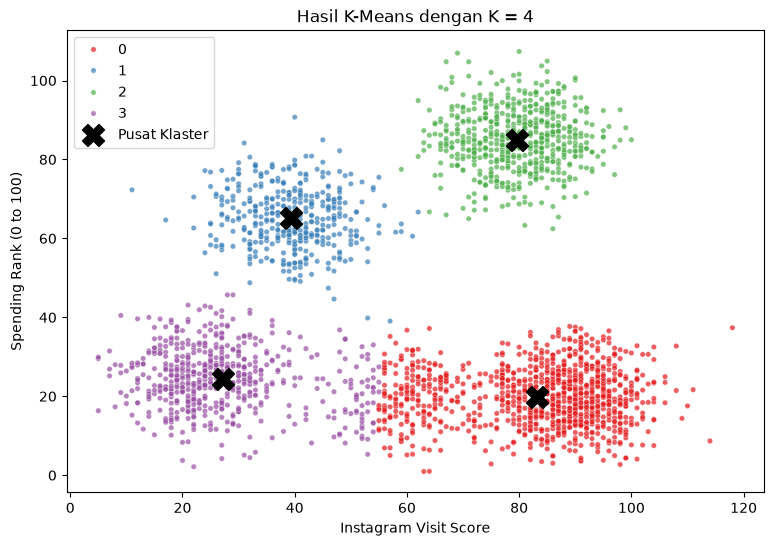

In [8]:
# Visualisasi hasil klasterisasi
plt.figure(figsize=(9, 6))
sns.scatterplot(x='Instagram visit score', y='Spending_rank(0 to 100)',
                hue='Klaster', data=data, palette='Set1', s=15, alpha=0.7)
plt.scatter(pusat[:, 0], pusat[:, 1], c='black', marker='X', s=250, label='Pusat Klaster')
plt.title(f'Hasil K-Means dengan K = {k_optimal}')
plt.xlabel('Instagram Visit Score')
plt.ylabel('Spending Rank (0 to 100)')
plt.legend()
plt.show()

#### Penjelasan:

Kode di atas untuk menampilkan hasil klasterisasi dalam bentuk grafik, dengan warna berbeda untuk tiap klaster dan tanda untuk pusat klaster.

Baris `sns.scatterplot(..., hue='Klaster', palette='Set1', s=15, alpha=0.7)` menggambar titik pengguna dan mewarnainya menurut klaster (`hue`). Pengaturan `s=15` mengatur ukuran titik dan `alpha=0.7` membuatnya agak transparan. Baris `plt.scatter(pusat[:, 0], pusat[:, 1], c='black', marker='X', s=250, label='Pusat Klaster')` menambahkan tanda X hitam besar di posisi pusat tiap klaster. Bagian `pusat[:, 0]` adalah nilai visit score semua pusat dan `pusat[:, 1]` adalah nilai spending rank semua pusat. Judul grafik memakai `f'...{k_optimal}'` sehingga angka K muncul otomatis.

**Cara membaca hasil:** terlihat empat kelompok yang terpisah cukup jelas, masing-masing dengan satu tanda X di tengahnya. Titik di tiap kelompok mengumpul di sekitar pusatnya, dan itulah inti K-Means: setiap pengguna masuk ke klaster yang pusatnya paling dekat. Dua klaster di bagian bawah (klaster 0 di kanan dan klaster 3 di kiri) agak berdekatan, dan ada sedikit titik di perbatasan keduanya di sekitar visit score 50 sampai 60. Dua klaster di bagian atas (klaster 1 dan klaster 2) terpisah lebih jelas.


In [9]:
# Profil tiap klaster
profil = data.groupby('Klaster').agg(
    jumlah_pengguna=('Klaster', 'count'),
    rata2_visit_score=('Instagram visit score', 'mean'),
    rata2_spending_rank=('Spending_rank(0 to 100)', 'mean')
).round(2)
profil

,jumlah_pengguna,rata2_visit_score,rata2_spending_rank
Klaster,,,
0,1027,83.24,19.87
1,400,39.35,65.13
2,600,79.61,85.02
3,573,27.30,24.31


#### Penjelasan:

Kode di atas untuk membuat profil tiap klaster, yaitu merangkum karakteristik rata-rata pengguna di setiap klaster. Profil ini dasar untuk menafsirkan hasil klasterisasi.

Perintah `data.groupby('Klaster')` mengelompokkan baris berdasarkan nomor klaster. Lalu `.agg(...)` menghitung beberapa ringkasan sekaligus untuk tiap kelompok dan memberi nama pada kolom hasilnya: `jumlah_pengguna` (jumlah anggota), `rata2_visit_score`, dan `rata2_spending_rank`. Fungsi `.round(2)` membulatkan hasilnya 2 angka di belakang koma.

**Cara membaca hasil dan analisa:**

Klaster 0 (1.027 pengguna, visit sekitar 83, spending sekitar 20) adalah pengguna yang **sangat sering membuka Instagram tetapi pengeluarannya rendah**. Mereka aktif di media sosial, tetapi belum banyak membelanjakan uang. Kelompok ini adalah yang terbesar.

Klaster 1 (400 pengguna, visit sekitar 39, spending sekitar 65) adalah pengguna yang **jarang sampai sedang membuka Instagram tetapi pengeluarannya cukup tinggi**. Mereka tidak terlalu aktif di media sosial, tetapi punya daya beli yang baik.

Klaster 2 (600 pengguna, visit sekitar 80, spending sekitar 85) adalah pengguna yang **sangat aktif di Instagram dan pengeluarannya paling tinggi**. Inilah kelompok pelanggan terbaik, sangat cocok untuk promosi lewat Instagram.

Klaster 3 (573 pengguna, visit sekitar 27, spending sekitar 24) adalah pengguna yang **jarang membuka Instagram dan pengeluarannya rendah**. Mereka kelompok yang paling pasif.

**Kesimpulan:** nilai K optimal adalah 4 (silhouette score tertinggi 0,6468 dan siku Elbow di sekitar 4), dan data terbagi menjadi empat segmen pengguna dengan perilaku berbeda. Hasil ini bisa dipakai untuk menyusun strategi pemasaran yang berbeda untuk tiap segmen. Misalnya mengubah pengguna klaster 0 yang aktif tetapi hemat menjadi lebih banyak berbelanja, dan mempertahankan pengguna klaster 2 yang sudah bernilai tinggi.
